# GameTheory-04i — Utilité espérée et aversion au risque
**Navigation** : [<< 4h-Routing-PriceOfAnarchy](GameTheory-04h-Routing-PriceOfAnarchy-Python.ipynb) | [Index](README.md) | [4j-Rationalisabilite >>](GameTheory-04j-Rationalisabilite-Python.ipynb)


Le carnet [GameTheory-04-NashEquilibrium-Python.ipynb](GameTheory-04-NashEquilibrium-Python.ipynb) calcule des équilibres de Nash en stratégies mixtes sur des matrices de paiements **numériques**. Mais d'où viennent ces nombres ? La condition d'indifférence qui détermine un équilibre mixte — « le gain espéré de chaque action jouée est égal » — compare des **espérances de nombres**, pas des classements : elle suppose que les paiements sont des **utilités cardinales**, construites depuis des préférences sur des loteries. Ce carnet construit ce chaînon manquant : le théorème de représentation de von Neumann-Morgenstern (vNM), l'élicitation d'une utilité normalisée, l'équivalence certaine et la prime de risque, puis — c'est sa contribution propre — il **mesure ce que l'aversion au risque fait aux équilibres des jeux mêmes du palier 04** (Dilemme du Prisonnier, Stag Hunt, Battle of the Sexes, Matching Pennies).

**Position dans la série** : accretion du palier 04 (les équilibres mixtes deviennent des équilibres *en utilités* ; le carnet [DecInfer-09-Theories-Decision-Predicteur-Python.ipynb](../Probas/DecisionTheory/DecInfer/DecInfer-09-Theories-Decision-Predicteur-Python.ipynb) couvre l'autre lecture des mixtes, comme croyances, et non comme utilités). Source primaire de ce port : [carnet Python versionné](GameTheory-04i-Utilite-Esperee-Risque-Python.ipynb). La bibliographie ci-dessous est héritée ; ce port ne revendique pas de nouvelle lecture.
**Prérequis** : .NET interactif, Python.NET 3.1.0, CPython compatible et `nashpy` avec ses dépendances. Le [chargeur partagé](../Config/PythonNetLoader.cs) choisit un interpréteur qui importe `nashpy`.


## Références

Les références bibliographiques sont reprises du carnet Python versionné. Nashpy est invoqué directement pour l’énumération des supports en section 6.


In [1]:
// Le chargeur sélectionne un CPython qui importe réellement Nashpy.
#r "nuget: pythonnet,3.1.0"
#load "../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Numerics;
using System.Text;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "nashpy");
using (Py.GIL())
{
    dynamic nash = Py.Import("nashpy");
    dynamic np = Py.Import("numpy");
    Console.WriteLine($"nashpy {nash.__version__} | numpy {np.__version__}");
}
record Svg(string Content);
Formatter.Register<Svg>((plot, writer) => writer.Write(plot.Content), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(Svg), "image/svg+xml");
Console.WriteLine("Calculs natifs C#, pont Nashpy et affichage SVG initialisés.");


Installed Packages pythonnet, 3.1.0

nashpy 0.0.43 | numpy 2.5.4


Calculs natifs C#, pont Nashpy et affichage SVG initialisés.


## 1. Loteries d'argent et attitudes face au risque

Une **loterie d'argent** est une distribution de probabilité sur des montants : $L = \left(\$x_1, \dots, \$x_n;\ p_1, \dots, p_n\right)$. Sa valeur espérée est $\mathbb{E}[L] = \sum_i p_i x_i$. Bonanno (§4.1) classe les attitudes face au risque **par rapport à la valeur espérée** (Définition 4.1) : un individu est **averse au risque** s'il préfère (ou est indifférent à) recevoir $\mathbb{E}[L]$ avec certitude plutôt que de jouer $L$ ; **risque-neutre** s'il est indifférent ; **risque-aimant** dans le cas contraire.

In [2]:
// Une loterie conserve les montants et les probabilités pour tous les calculs suivants.
class Loterie
{
    public double[] Montants { get; }
    public double[] Probs { get; }

    public Loterie(double[] montants, double[] probs)
    {
        if (
            montants.Length != probs.Length
            || montants.Length == 0
            || probs.Any(p => p < 0)
            || Math.Abs(probs.Sum() - 1) > 1e-12
        )
            throw new ArgumentException("Probabilités invalides");
        Montants = montants;
        Probs = probs;
    }

    public double Esperance() => Montants.Zip(Probs, (m, p) => m * p).Sum();

    public double UtiliteEsperee(Func<double, double> u) =>
        Montants.Zip(Probs, (m, p) => u(m) * p).Sum();

    public void Affiche(string nom) =>
        Console.WriteLine(
            $"{nom} = ({string.Join(", ", Montants.Zip(Probs, (m, p) => $"${m:F0} @ {p:G4}"))})   E[{nom}] = ${Esperance():F2}"
        );
}

var L1 = new Loterie(new[] { 30.0, 45, 90 }, new[] { 1.0 / 3, 5.0 / 9, 1.0 / 9 });
var L2 = new Loterie(new[] { 5.0, 100 }, new[] { .6, .4 });
L1.Affiche("L1");
L2.Affiche("L2");
Console.WriteLine("Risque neutre : 45 > 43, donc L1 > L2.");



L1 = ($30 @ 0.3333, $45 @ 0.5556, $90 @ 0.1111)   E[L1] = $45.00


L2 = ($5 @ 0.6, $100 @ 0.4)   E[L2] = $43.00


Risque neutre : 45 > 43, donc L1 > L2.


### Le classement de deux loteries arbitraires ne suit pas de l'attitude face au risque

Connaître l'attitude d'un individu (déf. 4.1) ne **suffit pas** à prédire comment il classe deux loteries arbitraires. Le contre-exemple du chapitre (exercice 4.11) : $L_3 = \$28$ certain et $L_4 = (\$10, \$50;\ \tfrac{1}{2}, \tfrac{1}{2})$ avec $\mathbb{E}[L_4] = \$30 > \$28$. **Ann** a l'utilité $U_{Ann}(m) = \sqrt{m}$ ; **Bob** l'utilité concave $U_{Bob}(m) = m - m^2/1000$ (construite sur le modèle de l'exercice). Vérifions les trois faits : chacun est averse au risque au sens de la définition, et pourtant leurs classements s'opposent.

In [3]:
// Comparer chaque utilité de loterie à celle de son espérance certaine.
var L3 = new Loterie(new[] { 28.0 }, new[] { 1.0 });
var L4 = new Loterie(new[] { 10.0, 50 }, new[] { .5, .5 });
Func<double, double> sqrt = Math.Sqrt;
Func<double, double> bob = m => m - m * m / 1000;
foreach (var (name, u) in new[] { ("Ann (sqrt)", sqrt), ("Bob (m - m²/1000)", bob) })
{
    double eu3 = L3.UtiliteEsperee(u),
        eu4 = L4.UtiliteEsperee(u),
        certain = u(30);
    Console.WriteLine(
        $"{name} EU(L3)={eu3:F4}, EU(L4)={eu4:F4}, U(30)={certain:F4} ; {(eu3 > eu4 ? "L3 > L4" : "L4 > L3")} ; {(certain > eu4 ? "averse" : "non averse")}"
    );
}


Ann (sqrt) EU(L3)=5.2915, EU(L4)=5.1167, U(30)=5.4772 ; L3 > L4 ; averse


Bob (m - m²/1000) EU(L3)=27.2160, EU(L4)=28.7000, U(30)=29.1000 ; L4 > L3 ; averse


### Interprétation : deux averses au risque, deux classements

Ann préfère $L_3$ : la racine carrée pénalise assez le gain espéré supplémentaire ($30 contre $28) pour préférer la certitude. Bob préfère $L_4$ : sa concavité est faible, l'écart d'espérance ($2) domine. **Tous deux sont averses au risque** — chacun préfère $30 certains à $L_4$ — et pourtant ils classent $L_3$ et $L_4$ en sens opposés. La définition 4.1 qualifie une attitude *localement* (face à la valeur espérée) ; le classement *global* des loteries exige une fonction d'utilité complète : c'est l'objet du théorème de représentation.

## 2. Le théorème de représentation de von Neumann-Morgenstern

**Théorème 4.1 (Bonanno, ch. 4).** Si les préférences $\succsim$ sur les loteries satisfont quatre axiomes (section 4 ci-dessous), il existe une fonction $U$ sur les résultats de base telle que, pour toutes loteries $L, L'$ :

$$L \succ L' \iff \mathbb{E}[U(L)] > \mathbb{E}[U(L')]$$

**Théorème 4.2.** $U$ est unique **à transformation affine positive près** : si $U$ représente $\succsim$, alors $V = aU + b$ ($a > 0$) aussi, et toute autre représentation est de cette forme. C'est ce qui rend l'utilité **cardinale** : les *différences* d'utilité ont un sens (à un facteur d'échelle près), contrairement à l'utilité ordinale du ch. 1 — et c'est exactement ce dont la condition d'indifférence d'un équilibre mixte a besoin.

Une conséquence immédiate et puissante (l'exemple « Susan » du chapitre) : si Susan préfère $A = (o_2, o_3;\ 0.25, 0.75)$ à $B = (o_1, o_3;\ 0.2, 0.8)$, alors on peut **prédire** sans connaître $U$ qu'elle préfère $D = o_2$ certain à $C = (o_1, o_3;\ 0.8, 0.2)$ — car $\mathbb{E}[U(A)] > \mathbb{E}[U(B)]$ se réécrit $U(o_2) > 0.8\,U(o_1) + 0.2\,U(o_3)$. Mesurons la robustesse de cette prédiction à l'échelle affine.

In [4]:
bool InvarianceAffine(Func<double, double> u, double a, double b, Loterie[] ls)
{
    var order = Enumerable.Range(0, ls.Length).OrderByDescending(i => ls[i].UtiliteEsperee(u));
    var transformed = Enumerable
        .Range(0, ls.Length)
        .OrderByDescending(i => a * ls[i].UtiliteEsperee(u) + b);
    return order.SequenceEqual(transformed);
}
var LA = new Loterie(new[] { 3.0, 2 }, new[] { .5, .5 });
var LB = new Loterie(new[] { 3.0 }, new[] { 1.0 });
var LC = new Loterie(new[] { 2.0, 3 }, new[] { .7, .3 });
var lotteries = new[] { LA, LB, LC };
var noms = new[] { "LA", "LB", "LC" };
Console.WriteLine(
    $"U=sqrt : {string.Join(" > ", Enumerable.Range(0, 3).OrderByDescending(i => lotteries[i].UtiliteEsperee(sqrt)).Select(i => noms[i]))}"
);
foreach (var (a, b) in new[] { (3.0, 2.0), (.1, -5.0), (-1.0, 7.0) })
    Console.WriteLine(
        $"V={a}U+{b} : classement conservé = {InvarianceAffine(sqrt, a, b, lotteries)}"
    );

// La prédiction de Susan compare D=o2 à C=.8 o1+.2 o3.
bool PredictionSusan(double u1, double u2, double u3) =>
    (.25 * u2 + .75 * u3 > .2 * u1 + .8 * u3) == (u2 > .8 * u1 + .2 * u3);
var random = new Random(7);
int passed = 0;
for (int i = 0; i < 10000; i++)
    if (
        PredictionSusan(
            10 * random.NextDouble(),
            10 * random.NextDouble(),
            10 * random.NextDouble()
        )
    )
        passed++;
Console.WriteLine($"Susan : {passed}/10000 triplets vérifient l'équivalence.");


U=sqrt : LB > LA > LC


V=3U+2 : classement conservé = True


V=0.1U+-5 : classement conservé = True


V=-1U+7 : classement conservé = False


Susan : 10000/10000 triplets vérifient l'équivalence.


### Interprétation : l'échelle est arbitraire, l'ordre ne l'est pas

Toute transformation affine **positive** de $U$ conserve le classement des loteries ; une transformation **négative** le renverse. L'utilité vNM est donc une échelle de température : le zéro et l'unité sont conventionnels, mais les rapports de différences — $\frac{U(x)-U(y)}{U(z)-U(w)}$ — sont invariants. C'est pourquoi l'on peut **normaliser** $U$ sans perte (section suivante), et pourquoi un équilibre mixte — qui égalise des différences d'espérances — a un sens que la seule information ordinale ne peut pas porter.

## 3. Utilité normalisée et élicitation par équivalence de probabilité

**Définition 4.3 (normalisation).** Fixons $U(o_{best}) = 1$ et $U(o_{worst}) = 0$ — licite par le théorème 4.2. Alors pour tout résultat $o$, l'axiome de continuité garantit l'existence d'un $p$ tel que $o \sim (o_{best}, o_{worst};\ p, 1-p)$, et la normalisation donne exactement $U(o) = p$. **Éliciter** l'utilité d'un individu revient donc à lui poser des questions d'indifférence : « pour quelle probabilité $p$ êtes-vous indifférent entre $o$ et un tirage qui donne $o_{best}$ avec proba $p$, $o_{worst}$ sinon ? ». Avec $m$ résultats, $m-2$ questions suffisent (les deux extrêmes sont fixés par convention).

In [5]:
// La table normalise les deux extrêmes et conserve les réponses déclarées.
Dictionary<string, double> Elicite(
    Dictionary<string, double> indifferent,
    string best,
    string worst
)
{
    var table = new Dictionary<string, double> { { best, 1 }, { worst, 0 } };
    foreach (var (key, value) in indifferent)
        table[key] = value;
    return table;
}
var table = Elicite(new Dictionary<string, double> { { "o1", .4 }, { "o5", .4 } }, "o2", "o3");
foreach (var o in new[] { "o1", "o2", "o3", "o4", "o5" })
    Console.WriteLine(
        $"U({o}) = {(table.TryGetValue(o, out var v) ? v : 0):F2}{(o == "o4" ? " (indifférent au pire)" : "")}"
    );
if (table["o1"] <= table["o3"])
    throw new Exception("Classement incohérent");
Console.WriteLine("Contrôle : U(o1) > U(o3).");


U(o1) = 0.40


U(o2) = 1.00


U(o3) = 0.00


U(o4) = 0.00 (indifférent au pire)


U(o5) = 0.40


Contrôle : U(o1) > U(o3).


### Interprétation : la probabilité d'indifférence EST l'utilité

Une fois les extrêmes normalisés à 1 et 0, chaque réponse d'indifférence fournit directement une valeur d'utilité : ici $U = (0.4,\ 1,\ 0,\ 0,\ 0.4)$ sur $(o_1, o_2, o_3, o_4, o_5)$. Trois questions ont suffi pour cinq résultats. Ce protocole — dit d'**équivalence de probabilité** — est celui qu'utilisent l'économie expérimentale et la théorie de la décision pour mesurer l'utilité d'un individu ; la section 5 l'applique à des montants en euros.

### Exercice 1 : élicitation sur six résultats

Six montants $m_1 > m_2 > \dots > m_6$. Élicitez l'utilité normalisée par quatre questions d'indifférence ($m_2, m_3, m_4, m_5$), puis vérifiez la cohérence : $U(m_3)$ doit rester strictement entre $U(m_2)$ et $U(m_4)$. Indice : $U(m_1) = 1$, $U(m_6) = 0$, et chaque réponse d'indifférence $m_i \sim (m_1, m_6; p_i, 1-p_i)$ donne directement $U(m_i) = p_i$.

**Implémentation C#** : Complétez `exercice1` : renvoyez la table contenant les quatre probabilités, `m1=1` et `m6=0`. Vérifiez la décroissance stricte. Plusieurs tables servent de sondes.

In [6]:
// Exercice 1 : compléter la table normalisée à partir des quatre réponses.
Func<Dictionary<string, double>, Dictionary<string, double>> exercice1 = reponses =>
{
    // TODO : m1 vaut 1, m6 vaut 0 ; recopier les quatre réponses.
    return null;
};
var cases1 = new[]
{
    new Dictionary<string, double>
    {
        { "m2", .8 },
        { "m3", .5 },
        { "m4", .3 },
        { "m5", .1 },
    },
    new Dictionary<string, double>
    {
        { "m2", .9 },
        { "m3", .7 },
        { "m4", .4 },
        { "m5", .2 },
    },
};
var answers1 = cases1.Select(x => exercice1(new Dictionary<string, double>(x))).ToArray();
if (answers1.All(x => x == null))
    Console.WriteLine("Exercice 1 à compléter");
else
{
    for (int i = 0; i < cases1.Length; i++)
    {
        var t = answers1[i];
        if (
            t == null
            || t.Count != 6
            || !t.TryGetValue("m1", out var best)
            || best != 1
            || !t.TryGetValue("m6", out var worst)
            || worst != 0
            || cases1[i].Any(x => !t.TryGetValue(x.Key, out var v) || v != x.Value)
        )
            throw new Exception("Élicitation incorrecte");
        if (!(t["m2"] > t["m3"] && t["m3"] > t["m4"] && t["m4"] > t["m5"]))
            throw new Exception("Ordre incohérent");
    }
    Console.WriteLine("Exercice 1 : tables vérifiées");
}


Exercice 1 à compléter


## 4. Les quatre axiomes et la réduction des loteries composées

Le théorème 4.1 repose sur quatre axiomes (Bonanno, §4.3) : **(1)** complétude et transitivité des préférences sur les loteries ; **(2)** monotonicité (plus d'argent est préféré) ; **(3)** continuité (pas de saut infinitésimal : l'indifférence $o \sim (o_{best}, o_{worst}; p, 1-p)$ existe) ; **(4)** indépendance (substituabilité) : si $L \sim L'$, alors remplacer $L$ par $L'$ **au sein d'une loterie composée** ne change pas les préférences. L'axiome 4 a une conséquence calculable : une loterie composée (un tirage dont les prix sont eux-mêmes des loteries) est équivalente à la **loterie simple** obtenue en multipliant les probabilités le long des branches de l'arbre — exactement la mécanique de la Figure 4.2 du chapitre.

In [7]:
// Fraction exacte normalisée ; le dénominateur reste positif.
record struct Fraction
{
    public BigInteger Numerator { get; }
    public BigInteger Denominator { get; }

    public Fraction(BigInteger n, BigInteger d)
    {
        if (d == 0)
            throw new ArgumentException("Dénominateur nul");
        if (d < 0)
        {
            n = -n;
            d = -d;
        }
        var gcd = BigInteger.GreatestCommonDivisor(BigInteger.Abs(n), d);
        Numerator = n / gcd;
        Denominator = d / gcd;
    }

    public static Fraction operator +(Fraction x, Fraction y) =>
        new(x.Numerator * y.Denominator + y.Numerator * x.Denominator, x.Denominator * y.Denominator);

    public static Fraction operator *(Fraction x, Fraction y) =>
        new(x.Numerator * y.Numerator, x.Denominator * y.Denominator);

    public double Valeur() => (double)Numerator / (double)Denominator;
    public override string ToString() => Denominator == 1 ? $"{Numerator}" : $"{Numerator}/{Denominator}";
}
record Branche(Fraction Proba, string Resultat, Branche[] Enfants);
Fraction F(int n, int d = 1) => new Fraction(n, d);
Branche Feuille(string s, int n, int d = 1) => new Branche(F(n, d), s, Array.Empty<Branche>());
Branche Noeud(int n, int d, params Branche[] branches) => new Branche(F(n, d), null, branches);
var branches = new[]
{
    Noeud(1, 3, Feuille("o1", 1, 2), Noeud(1, 2, Feuille("o3", 1, 3), Noeud(2, 3, Feuille("o2", 1, 2), Feuille("o4", 1, 2)))),
    Noeud(2, 3, Feuille("o1", 1, 4), Feuille("o2", 0), Noeud(3, 4, Feuille("o3", 1, 5), Feuille("o4", 4, 5)))
};
void Reduit(Fraction poids, Branche node, Dictionary<string, Fraction> acc)
{
    var chemin = poids * node.Proba;
    if (node.Resultat != null)
        acc[node.Resultat] = acc.GetValueOrDefault(node.Resultat, F(0)) + chemin;
    else
        foreach (var enfant in node.Enfants)
            Reduit(chemin, enfant, acc);
}
var probas = new Dictionary<string, Fraction>();
foreach (var branche in branches)
    Reduit(F(1), branche, probas);
var total = F(0);
foreach (var pair in probas.OrderBy(x => x.Key))
{
    Console.WriteLine($"P({pair.Key}) = {pair.Value} = {pair.Value.Valeur():F6}");
    total += pair.Value;
}
if (total != F(1))
    throw new Exception("La somme doit valoir 1");
Console.WriteLine($"Somme = {total} ; contrôle P(o1) = {F(1,3)*F(1,2)+F(2,3)*F(1,4)}");


P(o1) = 1/3 = 0.333333


P(o2) = 1/18 = 0.055556


P(o3) = 7/45 = 0.155556


P(o4) = 41/90 = 0.455556


Somme = 1 ; contrôle P(o1) = 1/3


### Interprétation : l'axiome d'indépendance fait le calcul

La loterie composée se réduit exactement — en fractions rationnelles, sans aucune approximation — en multipliant les probabilités le long de chaque chemin de l'arbre puis en sommant par résultat, et la somme vaut exactement 1. C'est l'axiome d'indépendance qui **autorise** cette réduction : traiter une loterie comme un prix substituable dans une loterie plus grande. C'est aussi l'axiome le plus discuté de la théorie (paradoxe d'Allais) — mais sans lui, l'équivalence « composer = réduire » disparaît, et avec elle l'interprétation des stratégies mixtes comme tirages uniques.

## 5. Équivalence certaine et prime de risque

Une fois $U$ connue, chaque loterie $L$ a un **équivalent certain** $CE(L) = U^{-1}(\mathbb{E}[U(L)])$ : le montant certain qui laisse l'individu exactement aussi satisfait que la loterie. Pour un individu averse au risque ($U$ concave et strictement croissante), la concavité (inégalité de Jensen) donne $CE(L) \le \mathbb{E}[L]$ ; l'écart $\pi(L) = \mathbb{E}[L] - CE(L) \ge 0$ est la **prime de risque** — le montant que l'individu est prêt à payer pour éliminer le risque. La définition 4.1 de la section 1 se relit alors : averse au risque $\iff$ prime de risque (faiblement) positive sur toute loterie.

L_mix = ($3 @ 0.24, $2 @ 0.24, $0 @ 0.52)   E[L_mix] = $1.20


E=1.200 ; CE sqrt=0.570, prime=0.630 ; CE log=0.816, prime=0.384


Prime k=0 : -0.0000 | k=20 : 2.087 | k=40 : 10.000


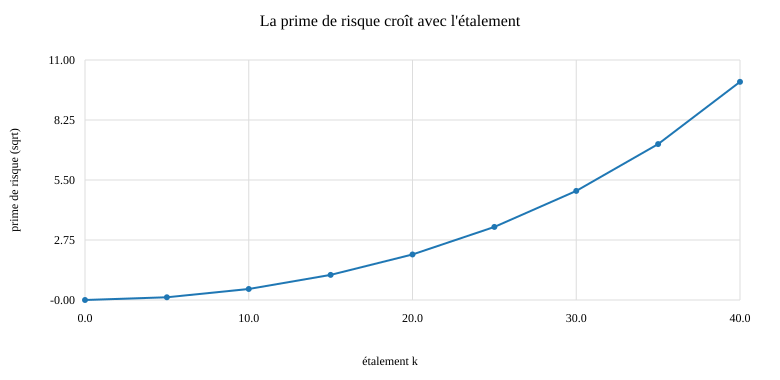

In [8]:
double EquivalentCertain(Loterie l, Func<double, double> u, Func<double, double> inverse) =>
    inverse(l.UtiliteEsperee(u));
Func<double, double> log = m => Math.Log(m + 1);
Func<double, double> invLog = u => Math.Exp(u) - 1;
double p = .6,
    q = .4;
var lMix = new Loterie(
    new[] { 3.0, 2, 0 },
    new[] { p * q, (1 - p) * (1 - q), 1 - p * q - (1 - p) * (1 - q) }
);
lMix.Affiche("L_mix");
double e = lMix.Esperance(),
    ceSqrt = EquivalentCertain(lMix, sqrt, u => u * u),
    ceLog = EquivalentCertain(lMix, log, invLog);
Console.WriteLine(
    $"E={e:F3} ; CE sqrt={ceSqrt:F3}, prime={e - ceSqrt:F3} ; CE log={ceLog:F3}, prime={e - ceLog:F3}"
);
var ks = Enumerable.Range(0, 9).Select(i => 5.0 * i).ToArray();
var primes = ks.Select(k =>
    {
        var l = new Loterie(new[] { 50 - k, 50 + k }, new[] { .5, .5 });
        return l.Esperance() - EquivalentCertain(l, sqrt, u => u * u);
    })
    .ToArray();
Console.WriteLine($"Prime k=0 : {primes[0]:F4} | k=20 : {primes[4]:F3} | k=40 : {primes[8]:F3}");

// La courbe utilise les points calculés ci-dessus, avec des axes et un fond opaques.
string Courbe(
    double[] xs,
    double[] ys,
    string title,
    string xlabel,
    string ylabel,
    double? reference = null
)
{
    const int width = 780,
        height = 380;
    double left = 85,
        right = 740,
        top = 60,
        bottom = 300;
    double xmin = xs.Min(),
        xmax = xs.Max(),
        ymin = Math.Min(0, ys.Min()),
        ymax = ys.Max() * 1.1;
    if (reference.HasValue)
    {
        ymin = Math.Min(ymin, reference.Value);
        ymax = Math.Max(ymax, reference.Value * 1.1);
    }
    double X(double x) => left + (x - xmin) / (xmax - xmin) * (right - left);
    double Y(double y) => bottom - (y - ymin) / (ymax - ymin) * (bottom - top);
    var s = new StringBuilder(
        $"<svg xmlns='http://www.w3.org/2000/svg' width='{width}' height='{height}' viewBox='0 0 {width} {height}'><rect width='100%' height='100%' fill='white'/><text x='390' y='26' text-anchor='middle' font-size='16'>{title}</text><text x='390' y='365' text-anchor='middle'>{xlabel}</text><text transform='translate(18,180) rotate(-90)' text-anchor='middle'>{ylabel}</text>"
    );
    for (int i = 0; i <= 4; i++)
    {
        double x = xmin + (xmax - xmin) * i / 4,
            y = ymin + (ymax - ymin) * i / 4;
        s.Append(
            $"<line x1='{X(x):F2}' y1='{top}' x2='{X(x):F2}' y2='{bottom}' stroke='#ddd'/><text x='{X(x):F2}' y='322' text-anchor='middle' font-size='12'>{x:F1}</text>"
        );
        s.Append(
            $"<line x1='{left}' y1='{Y(y):F2}' x2='{right}' y2='{Y(y):F2}' stroke='#ddd'/><text x='75' y='{Y(y) + 4:F2}' text-anchor='end' font-size='12'>{y:F2}</text>"
        );
    }
    if (reference.HasValue)
        s.Append(
            $"<line x1='{left}' y1='{Y(reference.Value):F2}' x2='{right}' y2='{Y(reference.Value):F2}' stroke='#888' stroke-dasharray='5 4'/><text x='650' y='{Y(reference.Value) - 6:F2}' font-size='12'>seuil neutre 0.75</text>"
        );
    if (reference.HasValue && xmin <= 1 && xmax >= 1)
        s.Append($"<line x1='{X(1):F2}' y1='{top}' x2='{X(1):F2}' y2='{bottom}' stroke='#888' stroke-dasharray='2 4'/>");
    var points = string.Join(" ", xs.Select((x, i) => $"{X(x):F2},{Y(ys[i]):F2}"));
    s.Append($"<polyline points='{points}' fill='none' stroke='#1f77b4' stroke-width='2'/>");
    if (xs.Length <= 10)
        for (int i = 0; i < xs.Length; i++)
            s.Append($"<circle cx='{X(xs[i]):F2}' cy='{Y(ys[i]):F2}' r='3' fill='#1f77b4'/>");
    return s.Append("</svg>").ToString();
}
display(
    new Svg(
        Courbe(
            ks,
            primes,
            "La prime de risque croît avec l'étalement",
            "étalement k",
            "prime de risque (sqrt)"
        )
    )
);


### Interprétation : le risque se paie, et se paie de plus en plus

La loterie de paiement de l'équilibre mixte du Battle of the Sexes a une espérance de **1,2** (le gain que le carnet 04 affiche) ; un joueur d'utilité $\sqrt{m}$ n'y accorde que l'équivalent certain calculé ci-dessus — la différence est le prix qu'il accorde au risque de méscoordination (52 % des tirages tombent sur un rendez-vous manqué). Sur la famille à espérance constante 50, la prime de risque croît avec l'étalement $k$ : à espérance égale, **plus le risque est dispersé, plus il coûte cher** à un individu aversé. La section suivante montre que ce prix n'est pas un simple confort psychologique : il **déplace les équilibres** des jeux du palier 04.

### Exercice 2 : prime de risque croissante sous utilité logarithmique

Construisez les loteries $(50-k, 50+k; \tfrac{1}{2}, \tfrac{1}{2})$ pour $k = 0, 5, \dots, 40$ sous $U(m) = \log(1+m)$, calculez les primes de risque et vérifiez qu'elles croissent avec $k$. Indice : $CE = U^{-1}(\mathbb{E}[U(L)])$ avec $U^{-1}(u) = e^u - 1$ ; prime $= 50 - CE$.

**Implémentation C#** : Complétez `exercice2` : renvoyez les neuf couples `(k, prime)` pour `k=0,5,...,40`. Utilisez `EquivalentCertain` et la fonction logarithmique ; les primes doivent être non décroissantes.

In [9]:
// Exercice 2 : primes logarithmiques pour les neuf valeurs de k.
Func<List<(double K, double Prime)>> exercice2 = () =>
{
    // TODO : construire les loteries, calculer équivalent certain et prime.
    return null;
};
var answer2 = exercice2();
if (answer2 == null)
    Console.WriteLine("Exercice 2 à compléter");
else
{
    if (answer2.Count != ks.Length)
        throw new Exception("Neuf mesures requises");
    for (int i = 0; i < ks.Length; i++)
    {
        var l = new Loterie(new[] { 50 - ks[i], 50 + ks[i] }, new[] { .5, .5 });
        double expected = l.Esperance() - EquivalentCertain(l, log, invLog);
        if (
            answer2[i].K != ks[i]
            || !double.IsFinite(answer2[i].Prime)
            || Math.Abs(answer2[i].Prime - expected) > 1e-10
            || (i > 0 && answer2[i].Prime < answer2[i - 1].Prime - 1e-10)
        )
            throw new Exception("Prime incorrecte");
    }
    Console.WriteLine("Exercice 2 : neuf primes vérifiées");
}


Exercice 2 à compléter


## 6. Le pont vers le palier 04 : l'aversion au risque déplace les équilibres mixtes

Les matrices du carnet 04 — Dilemme du Prisonnier $\begin{pmatrix}3&0\\5&1\end{pmatrix}$, Stag Hunt $\begin{pmatrix}4&0\\3&3\end{pmatrix}$, Battle of the Sexes $\begin{pmatrix}3&0\\0&2\end{pmatrix}$ pour Row, avec $B=\begin{pmatrix}2&0\\0&3\end{pmatrix}$ pour Col — sont des **utilités**. Si leurs paiements se lisent en euros, un joueur aversé au risque ne joue pas ce jeu-là : il joue le jeu transformé $U(A), U(B)$. Or la théorie prédit deux destins très différents : les **équilibres purs** ne dépendent que de l'ordre des paiements (meilleures réponses), donc survivent à toute transformation strictement croissante ; les **équilibres mixtes** égalisent des différences d'espérances — des grandeurs cardinales — donc **bougent** avec la courbure de $U$. Mesurons les trois jeux, avec les utilités neutre $U(m) = m$, averse $U(m) = \sqrt{m}$ et risque-aimant $U(m) = m^{1.5}$.

In [10]:
// Seul ce pont délègue à Nashpy : le jeu et l'énumération des supports sont réels.
List<(double[] Row, double[] Col)> NashEquilibria(double[,] a, double[,] b)
{
    using (Py.GIL())
    {
        using var np = Py.Import("numpy");
        using var nash = Py.Import("nashpy");
        using var rowsA = new PyList();
        using var rowsB = new PyList();
        for (int i = 0; i < 2; i++)
        {
            using var ra = new PyList();
            using var rb = new PyList();
            for (int j = 0; j < 2; j++)
            {
                using var pa = new PyFloat(a[i, j]);
                using var pb = new PyFloat(b[i, j]);
                ra.Append(pa);
                rb.Append(pb);
            }
            rowsA.Append(ra);
            rowsB.Append(rb);
        }
        using var arrayA = np.InvokeMethod("array", new PyObject[] { rowsA });
        using var arrayB = np.InvokeMethod("array", new PyObject[] { rowsB });
        using var game = nash.GetAttr("Game").Invoke(new[] { arrayA, arrayB });
        using var iterator = game.InvokeMethod("support_enumeration");
        using var builtins = Py.Import("builtins");
        using var list = builtins.InvokeMethod("list", new[] { iterator });
        var eqs = new List<(double[], double[])>();
        for (int i = 0; i < list.Length(); i++)
        {
            using var pair = list[i];
            using var r = pair[0];
            using var c = pair[1];
            using var r0 = r[0];
            using var r1 = r[1];
            using var c0 = c[0];
            using var c1 = c[1];
            eqs.Add((
                new[] { r0.As<double>(), r1.As<double>() },
                new[] { c0.As<double>(), c1.As<double>() }
            ));
        }
        return eqs;
    }
}
double[,] Transform(double[,] m, Func<double, double> u)
{
    var result = new double[m.GetLength(0), m.GetLength(1)];
    for (int i = 0; i < m.GetLength(0); i++)
    for (int j = 0; j < m.GetLength(1); j++)
        result[i, j] = u(m[i, j]);
    return result;
}
var utilities = new (string Name, Func<double, double> U)[]
{
    ("neutre", m => m),
    ("averse", sqrt),
    ("aimant", m => Math.Pow(m, 1.5)),
};
var aPd = new double[,]
{
    { 3, 0 },
    { 5, 1 },
};
var bPd = new double[,]
{
    { 3, 5 },
    { 0, 1 },
};
foreach (var (name, u) in utilities)
{
    var a = Transform(aPd, u);
    var b = Transform(bPd, u);
    var eqs = NashEquilibria(a, b);
    Console.WriteLine(
        $"{name} : domination={a[1, 0] > a[0, 0] && a[1, 1] > a[0, 1]} ; nashpy={eqs.Count} ; (Défaire,Défaire)={eqs.Any(x => Math.Abs(x.Row[1] - 1) < 1e-9 && Math.Abs(x.Col[1] - 1) < 1e-9)}"
    );
}


neutre : domination=True ; nashpy=1 ; (Défaire,Défaire)=True


averse : domination=True ; nashpy=1 ; (Défaire,Défaire)=True


aimant : domination=True ; nashpy=1 ; (Défaire,Défaire)=True


### Interprétation : les équilibres purs sont ordinalement robustes

Le Dilemme du Prisonnier garde son unique équilibre $(Defaire, Defaire)$ sous les trois utilités : une transformation strictement croissante ne peut pas inverser une domination stricte. Plus généralement, tout équilibre pur ne dépend que des **meilleures réponses** — une information ordinale. Un résultat du palier 04 portant sur les équilibres purs reste donc inchangé sous une relecture des paiements par une fonction strictement croissante ; c'est une robustesse **mesurable**, pas une intuition.

Une transformation seulement croissante au sens large peut aplatir des paiements distincts : elle peut ajouter des meilleures réponses et des équilibres purs. La conservation exacte invoquée ici exige donc la croissance stricte.


In [11]:
// Comparer la formule d’indifférence à l’énumération des supports Nashpy.
(double P, double Q) MixteInterieur(double[,] a, double[,] b)
{
    double q = (a[1, 1] - a[0, 1]) / (a[0, 0] - a[0, 1] - a[1, 0] + a[1, 1]);
    double p = (b[1, 1] - b[1, 0]) / (b[0, 0] - b[1, 0] - b[0, 1] + b[1, 1]);
    return (p, q);
}
var aBos = new double[,]
{
    { 3, 0 },
    { 0, 2 },
};
var bBos = new double[,]
{
    { 2, 0 },
    { 0, 3 },
};
foreach (var (name, u) in utilities)
{
    var a = Transform(aBos, u);
    var b = Transform(bBos, u);
    var (p0, q0) = MixteInterieur(a, b);
    var mixed = NashEquilibria(a, b).Where(x => x.Row[0] > 1e-6 && x.Row[0] < 1 - 1e-6).ToList();
    if (mixed.Count != 1)
        throw new Exception("Équilibre intérieur Nashpy absent ou multiple");
    Console.WriteLine(
        $"{name} : formule p={p0:F4}, q={q0:F4} ; Nashpy p={mixed[0].Row[0]:F4}, q={mixed[0].Col[0]:F4}"
    );
}
var neutral = MixteInterieur(aBos, bBos).P;
var riskAverse = MixteInterieur(Transform(aBos, sqrt), Transform(bBos, sqrt)).P;
Console.WriteLine(
    $"Déplacement de p : {neutral:F3} → {riskAverse:F3}, baisse {100 * (neutral - riskAverse) / neutral:F1}%."
);


neutre : formule p=0.6000, q=0.4000 ; Nashpy p=0.6000, q=0.4000


averse : formule p=0.5505, q=0.4495 ; Nashpy p=0.5505, q=0.4495


aimant : formule p=0.6475, q=0.3525 ; Nashpy p=0.6475, q=0.3525


Déplacement de p : 0.600 → 0.551, baisse 8.2%.


### Interprétation : l'équilibre mixte migre vers 50/50

Le résultat central du carnet : sous utilité neutre, l'équilibre mixte du Battle of the Sexes est $(p^*, q^*) = (0.6, 0.4)$ — le carnet 04 affiche exactement ces valeurs ; sous $\sqrt{m}$ les deux probabilités migrent **vers ½**, et sous utilité convexe elles s'en éloignent. La raison est structurelle : $q^*$ égalise $3q$ et $2(1-q)$ pour Row ; la transformation comprime l'écart $3$ vs $2$ en $\sqrt{3}$ vs $\sqrt{2}$ — un écart plus faible, donc un point d'indifférence plus proche de la symétrie. **La condition d'indifférence d'un équilibre mixte est une égalité de différences cardinales** : changer la courbure de l'utilité change l'équilibre, quand les équilibres purs (Opera-Opera, Football-Football) restent intacts. Les probabilités mixtes du palier 04 ne sont donc pas des propriétés du jeu « en euros » : ce sont des propriétés conjointes du jeu **et** de l'attitude face au risque des joueurs.

neutre : seuil Stag = 0.7500


averse : seuil Stag = 0.8660


gamma=0.4 : 0.8913 ; gamma=1.6 : 0.6311


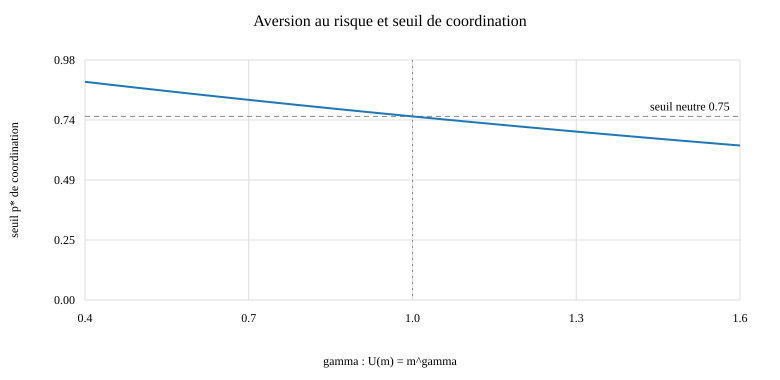

In [12]:
// Calculer 49 seuils de coordination en faisant varier la courbure.
var aStag = new double[,]
{
    { 4, 0 },
    { 3, 3 },
};
var bStag = new double[,]
{
    { 4, 3 },
    { 0, 3 },
};
foreach (var (name, u) in utilities.Take(2))
    Console.WriteLine(
        $"{name} : seuil Stag = {MixteInterieur(Transform(aStag, u), Transform(bStag, u)).P:F4}"
    );
var gammas = Enumerable.Range(0, 49).Select(i => .4 + 1.2 * i / 48).ToArray();
var thresholds = gammas
    .Select(g =>
        MixteInterieur(
            Transform(aStag, m => Math.Pow(m, g)),
            Transform(bStag, m => Math.Pow(m, g))
        ).P
    )
    .ToArray();
Console.WriteLine($"gamma=0.4 : {thresholds[0]:F4} ; gamma=1.6 : {thresholds[48]:F4}");
display(
    new Svg(
        Courbe(
            gammas,
            thresholds,
            "Aversion au risque et seuil de coordination",
            "gamma : U(m) = m^gamma",
            "seuil p* de coordination",
            .75
        )
    )
);


### Interprétation : l'aversion au risque durcit la coordination

Le seuil de coordination du Stag Hunt monte de $0.75$ (neutre) à $0.866$ sous $\sqrt{m}$ : il faut désormais une croyance plus élevée que l'autre chasse le cerf pour oser le chasser soi-même. La courbe en fonction de $\gamma$ est monotone : plus les joueurs sont averses au risque, plus le « bon » équilibre (chasse collective au cerf, gain 4) exige de confiance mutuelle — et un groupe d'individus averses se coordonne plus difficilement sur lui, alors même que cet équilibre est préféré par tous. **L'aversion au risque est un paramètre du jeu**, au même titre que les paiements eux-mêmes : la relire depuis les euros modifie les prédictions du palier 04 sur les équilibres mixtes, pas sur les équilibres purs.

### Exercice 3 : retransformer les jeux du palier 04

Appliquez $U(m) = \log(1+m)$ aux matrices du Dilemme du Prisonnier et du Stag Hunt du palier 04, recalculez les équilibres et comparez au cas neutre. Questions : (a) l'équilibre $(Defaire, Defaire)$ survit-il ? (b) le seuil de coordination du Stag Hunt monte-t-il, et de combien ? Indice : `Transform(A, log)` applique $\log(1+m)$ à toute la matrice ; la fonction `MixteInterieur(A, B)` est fournie en section 6.

**Implémentation C#** : Complétez `exercice3` : appliquez `log` aux matrices PD et Stag Hunt, appelez `NashEquilibria` et `MixteInterieur` ; renvoyez la survie de l’équilibre PD et les seuils Stag neutre et logarithmique.

In [13]:
// Exercice 3 : retransformer PD et Stag Hunt sous log(1+m).
Func<(bool Pd, double Neutre, double Log)?> exercice3 = () =>
{
    // TODO : appeler NashEquilibria et MixteInterieur pour les matrices indiquées.
    return null;
};
var answer3 = exercice3();
if (answer3 == null)
    Console.WriteLine("Exercice 3 à compléter");
else
{
    var pd = NashEquilibria(Transform(aPd, log), Transform(bPd, log));
    bool survives = pd.Any(x => Math.Abs(x.Row[1] - 1) < 1e-9 && Math.Abs(x.Col[1] - 1) < 1e-9);
    double neutralStag = MixteInterieur(aStag, bStag).P;
    double logStag = MixteInterieur(Transform(aStag, log), Transform(bStag, log)).P;
    if (
        answer3.Value.Pd != survives
        || !double.IsFinite(answer3.Value.Neutre)
        || !double.IsFinite(answer3.Value.Log)
        || Math.Abs(answer3.Value.Neutre - neutralStag) > 1e-10
        || Math.Abs(answer3.Value.Log - logStag) > 1e-10
    )
        throw new Exception("Résultat transformé incorrect");
    Console.WriteLine("Exercice 3 : équilibre et seuils vérifiés");
}


Exercice 3 à compléter


### Matching Pennies : le cas qui ne bouge pas

Le Matching Pennies du palier 04, $\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$ à somme nulle, garde son équilibre $(\tfrac{1}{2}, \tfrac{1}{2})$ sous toute transformation strictement croissante **symétrique** des paiements : la symétrie du jeu, pas la cardinalité, fixe l'équilibre. C'est le contrepoint utile des deux sections précédentes — le déplacement des équilibres mixtes par l'utilité est réel mais n'est pas universel : il apparaît quand les paiements des joueurs ne sont pas liés par une symétrie qui écrase l'effet de courbure. Les matrices du palier 04 sont donc à lire comme des **utilités** ; les convertir depuis des euros (ou non) est un choix de modélisation qui change les prédictions mixtes, et ce carnet fournit l'outillage (élicitation, section 3) pour le faire proprement.

## 7. Exercices

Trois activités pour s’approprier le pont loteries-jeux sont réparties au fil des mécanismes. Les squelettes s’exécutent sans erreur ; les TODO indiquent l’attendu et les indices la méthode.

1. **Élicitation sur six résultats** : calculer les utilités normalisées par équivalence de probabilité après la section 3.
2. **Prime de risque sous utilité logarithmique** : mesurer les équivalents certains et l’effet du risque après la section 5.
3. **Retransformer les jeux du palier 04** : comparer équilibres purs et distributions mixtes sous transformation d’utilité après la section 6.

Les trois énoncés complets, leurs indices et leurs cellules ouvertes restent à ces emplacements ; ce récapitulatif sert de repère dans le plan sans les dupliquer ni livrer les réponses.


## À retenir

| Concept | Énoncé | Où il est mesuré |
|---|---|---|
| **Attitude face au risque** (déf. 4.1) | classe $L$ contre $\mathbb{E}[L]$ certain | section 1 — Ann et Bob averses, classements opposés |
| **Théorème vNM** (4.1-4.2) | $L \succ L' \iff \mathbb{E}[U(L)] > \mathbb{E}[U(L')]$, $U$ unique à affine positive près | section 2 — invariance testée sur 3 transformations + prédiction de type Susan |
| **Élicitation normalisée** | $U(o) = p$ où $o \sim (o_{best}, o_{worst}; p, 1-p)$ | section 3 — table $(0.4, 1, 0, 0, 0.4)$ en trois questions |
| **Réduction** (axiome 4) | loterie composée $\equiv$ loterie simple, probabilités multipliées le long de l'arbre | section 4 — fractions exactes, somme $= 1$ |
| **Équivalent certain / prime** | $CE = U^{-1}(\mathbb{E}[U(L)])$, $\pi = \mathbb{E}[L] - CE$ | section 5 — loterie d'équilibre du BoS, courbe en $k$ |
| **Robustesse ordinale** | les équilibres purs survivent à toute transformation strictement croissante | section 6 — PD invariant sous 3 utilités |
| **Sensibilité cardinale** | les équilibres mixtes égalisent des différences : ils migrent avec $U$ | section 6 — BoS $0.6 \to 0.55$, Stag Hunt $0.75 \to 0.87$ |

**Le pont vers le palier 04** : les probabilités mixtes calculées dans le carnet 04 ne sont des prédictions sur un jeu d'argent qu'une fois choisie une attitude face au risque. Ce carnet fournit la chaîne complète : préférences $\to$ utilité élicitée $\to$ jeu transformé $\to$ équilibres recalculés — chaque maillon mesuré sur les matrices mêmes du palier.

**Quatre mesures à retenir.**

- **Deux averses peuvent classer différemment la même paire de loteries.** Sur `L3` (28 $ certain) et `L4` (10 $ ou 50 $ à 50 %, soit 30 $ d'espérance), Ann (`U = sqrt`) classe `L3` devant `L4` (`EU(L3) = 5.2915` contre `EU(L4) = 5.1167`) tandis que Bob (`U = m − m²/1000`) classe `L4` devant `L3` (`EU(L3) = 27.2160` contre `EU(L4) = 28.7000`). L'aversion au risque ne suffit donc pas à ordonner deux loteries risquées entre elles.
- **L'utilité espérée déplace les équilibres qui égalisent des différences, sans nécessairement les déplacer tous.** Sur la Battle of the Sexes, `p*` passe de `0.6000` (risque-neutre) à `0.5505` (averse) et à `0.6475` (aimant) ; sur le Stag Hunt, le seuil passe de `0.7500` à `0.8660`. Sur le Dilemme du Prisonnier, les trois utilités laissent le même équilibre unique `(Defaire, Defaire)`.
- **La prime de risque est l'écart entre espérance et équivalent certain : `$0.630` sous `U = sqrt` et `$0.384` sous `U = log(m+1)`**, sur la même loterie d'équilibre `E[L_mix] = $1.200`.
- **L'élicitation est univoque et la transformation affine est sans effet.** La table donne `U(o1) = 0.40`, `U(o2) = 1.00`, `U(o3) = 0.00` ; `V = 3U + 2` et `V = 0.1U − 5` conservent le classement, `V = −U + 7` ne le conserve pas.


## Vérifiez votre compréhension

1. Ann (`U = sqrt`) classe `L3` (28 $ certain) devant `L4` (10 $ ou 50 $ à 50 %) avec `EU(L3) = 5.2915` contre `EU(L4) = 5.1167`, et Bob (`U = m − m²/1000`) classe `L4` devant `L3` avec `EU(L3) = 27.2160` contre `EU(L4) = 28.7000`. Les deux sont averses : comment un même couple de loteries peut-il être classé opposément ?

   <details><summary>Réponse</summary>

   Parce que l'aversion au risque compare l'**espérance certaine** à l'**espérance risquée** : elle dit que 30 $ certains valent mieux que 10 $ ou 50 $ à parts égales, elle ne dit pas comment une loterie certaine et une autre loterie se classent entre elles. L3 a une espérance de 28 $, L4 de 30 $ : Ann, dont la concavité est très forte près de 0, préfère le certain ; Bob, dont la pénalité de variance est faible devant le gain d'espérance, préfère le risqué. Deux attitudes averses, deux classements — c'est l'exercice 4.11 de Bonanno, rejoué ici.

   </details>

2. L'utilité élicitée vaut `U(o1) = 0.40`, `U(o2) = 1.00`, `U(o3) = 0.00`, `U(o4) = 0.00`. Le cas `U(o3) = U(o4) = 0.00` est-il un défaut d'élicitation ?

   <details><summary>Réponse</summary>

   Non : `o3` et `o4` sont **indifférents** (le pire résultat du carnet), et la normalisation place les résultats indifférents au pire à 0. C'est une attente de la normalisation (`U(o_best) = 1`, `U(o_worst) = 0`), pas une collision accidentelle — et la table reste cohérente avec le classement déclaré (le contrôle `U(o1) > U(o3)` est vérifié).

   </details>

3. Sur la Battle of the Sexes, `p*` passe de `0.6000` à `0.5505` sous aversion, tandis que sur le Stag Hunt le seuil passe de `0.7500` à `0.8660`. L'aversion agit-elle dans le même sens dans les deux jeux ?

   <details><summary>Réponse</summary>

   Les deux probabilités viennent de conditions d'indifférence distinctes. Dans la Battle of the Sexes, `p*` est la probabilité d'Opéra : elle passe de `0.6000` à `0.5505` (environ 8,2 % de baisse), vers la symétrie `1/2`. La transformation comprime les différences de gains qui fixent cette indifférence. Dans le Stag Hunt, le seuil est la probabilité de Stag de l'adversaire qui rend le joueur indifférent : il passe de `0.7500` à `0.8660` (et à `0.8913` pour `gamma = 0.4`). La courbure de l'utilité déplace ainsi la distribution mixte dans le premier jeu et la croyance critique dans le second ; ces chiffres mesurent ces deux mécanismes.

   </details>

4. La prime de risque vaut `$0.630` sous `U = sqrt` et `$0.384` sous `U = log(m+1)` pour la même loterie (`E[L_mix] = $1.200`). Que mesure-t-elle exactement ?

   <details><summary>Réponse</summary>

   L'écart entre espérance et équivalent certain **pour une utilité donnée**. Elle est invariante par transformation affine positive de `U` (la même valeur certaine reste certaine), mais elle dépend de la **forme** de la concavité : ici les deux fonctions ne pénalisent pas de la même façon le résultat `$0` qui porte 52 % de la masse — la concavité de `sqrt` devient infinie en 0, celle de `log(m+1)` y vaut `-1`. Deux utilités ne sont pas deux mesures d'un même agent : comparer `$0.630` et `$0.384` n'a de sens qu'utilité fixée.

   </details>


## Pour aller plus loin

**Carnet suivant.** [GameTheory-04j — Rationalisabilité](GameTheory-04j-Rationalisabilite-Python.ipynb) -- ce que la seule rationalité peut délier : quand la connaissance commune des utilités cardinales n'est plus garantie, la condition de Nash elle-même s'effondre et l'on ne peut plus parler que de profils rationalisables.

**Lectures.**

- Les références complètes du carnet sont dans la section « Références académiques » : von Neumann & Morgenstern (1944) pour l'axiomatique originale, Bonanno (2015) ch. 4 pour le théorème de représentation et l'exercice 4.11 rejoué ici, Jensen (1906) pour l'inégalité de convexité qui fonde `CE(L) ≤ E[L]`, et Knight & Campbell (2018) pour `nashpy`, qui recalcule les équilibres des jeux transformés indépendamment de la formule d'indifférence.
- Le carnet [GameTheory-04 — Nash](GameTheory-04-NashEquilibrium-Python.ipynb) (sections 2 et 4) fournit les matrices dont cette section mesure la version transformée : c'est le même jeu, lu avec une utilité.
- La lecture **conjointe** des stratégies mixtes — comme croyances plutôt que comme utilités — est traitée dans [DecInfer-09 — Théories de la décision et prédicteur](../Probas/DecisionTheory/DecInfer/DecInfer-09-Theories-Decision-Predicteur-Python.ipynb).

**Carnets voisins.**

- [GameTheory-04 — Nash](GameTheory-04-NashEquilibrium-Python.ipynb) -- le track principal du palier : les équilibres mixtes dont ce carnet fournit la chaîne manquante (préférences → utilité → jeu transformé → équilibres recalculés).
- [GameTheory-04k — Équilibre corrélé](GameTheory-04k-Equilibre-Correle-Python.ipynb) -- l'autre moyen de dépasser l'équilibre de Nash : non plus changer les utilités, mais changer la **corrélation** des actions.


## Références académiques

Bibliographie héritée du carnet Python versionné ; aucune lecture nouvelle des articles n'est revendiquée.

1. **von Neumann, J. & Morgenstern, O. (1944).** *Theory of Games and Economic Behavior.* Princeton University Press. — l'axiomatique originale de l'utilité espérée (démonstration que des préférences satisfaisant les axiomes admettent une représentation linéaire en probabilités, unique à transformation affine positive près).
2. **Bonanno, G. (2015).** *Game Theory* (open access textbook, 165 solved exercises), ch. 4 « Expected Utility ». arXiv:1512.06808. — la source directe de ce carnet : définition 4.1 (attitudes), théorèmes 4.1-4.2 (représentation, unicité affine), exemple d'élicitation, axiomes 1-4 et réduction, exercice 4.11 (deux averses au risque aux classements opposés). Copie archivée dans le gisement cluster : `G:\Mon Drive\MyIA\IA\Bibliographie IA\GameTheory\` ; licence indiquée : CC BY-NC-ND 4.0.
3. **Knight, V. & Campbell, J. (2018).** *Nashpy: A Python library for the computation of Nash equilibria.* Journal of Open Source Software 3(30): 904. doi:10.21105/joss.00904. — recalcule ici les équilibres des jeux transformés (section 6), indépendamment de la formule d'indifférence.
4. **Jensen, J. L. W. V. (1906).** *Sur les fonctions convexes et les inégalités entre les valeurs moyennes.* Acta Mathematica 30: 175-193. — l'inégalité de convexité qui fonde $CE(L) \le \mathbb{E}[L]$ pour toute utilité concave (prime de risque positive de l'averse).

> **Lien avec le palier 04** : les jeux mesurés en section 6 sont exactement ceux de [GameTheory-04-NashEquilibrium-Python.ipynb](GameTheory-04-NashEquilibrium-Python.ipynb) (ses sections 2 et 4). La lecture « croyances » des stratégies mixtes est traitée dans [DecInfer-09-Theories-Decision-Predicteur-Python.ipynb](../Probas/DecisionTheory/DecInfer/DecInfer-09-Theories-Decision-Predicteur-Python.ipynb).

***